# 04 - NLP Sentiment Analysis Benchmarking & Model Evaluation

**Zahir Social Analytics — Evaluasi Komparatif 4 Metode Klasifikasi Sentimen Ulasan Google Play Store**

---

### Deskripsi & Tujuan Benchmarking
Notebook ini membandingkan performa empat paradigma pemodelan NLP dalam mengklasifikasikan sentimen ulasan pengguna (*Customer Voice*) ke dalam tiga kelas: `positive`, `neutral`, dan `negative`.

Empat model yang dievaluasi:
1. **Majority Class Baseline**: Baseline heuristik sederhana yang selalu memprediksi kelas mayoritas (`positive`).
2. **InSet Lexicon**: Pendekatan leksikon berbasis kamus sentimen bahasa Indonesia (*Indonesian Sentiment Lexicon*) dengan threshold polaritas (+/-2.0).
3. **TF-IDF + Logistic Regression**: Pendekatan machine learning klasik (*supervised n-gram TF-IDF vectorizer + regularized logistic regression*).
4. **IndoBERT Pretrained (Indo4B / IndoNLU - SmSA)**: Model transfer learning berbasis transformer bahasa Indonesia (*state-of-the-art deep contextual representation*).

### Integritas Metodologi & Pencegahan Data Leakage
- **Pembagian Data (Stratified 80/20)**:
  - **Development Set (Training & Tuning)**: 333 ulasan (80%).
  - **Held-Out Test Set (Evaluasi Akhir Murni)**: 84 ulasan (20%).
- **Pencegahan Kebocoran Data (*Data Leakage Prevention*)**:
  - Held-out test set **tidak pernah** dilihat atau digunakan selama proses pelatihan model, pembentukan leksikon, penyesuaian threshold, maupun kalkulasi IDF.
  - Model dievaluasi secara ketat hanya pada 84 ulasan test set yang identik.
  - Default notebook beroperasi dalam mode **Read-Only Analysis** menggunakan artefak prediksi resmi. Opsi retraining model disediakan melalui switch eksplisit yang dinonaktifkan secara default.

---

### Metadata Input & Output
- **File Input**:
  - `data/final/sentiment_benchmark/sentiment_split_manifest.csv` (Partisi 333 dev / 84 test).
  - `data/final/sentiment_benchmark/sentiment_benchmark_metrics.csv` (Metrik resmi 4 model).
  - `data/final/sentiment_benchmark/sentiment_test_predictions.csv` (Prediksi per-ulasan pada 84 data test).
  - `data/final/sentiment_benchmark/sentiment_error_analysis.csv` (Kasus kesalahan klasifikasi).
- **Output Artefak**:
  - Output grafik: `outputs/figures/sentiment_benchmark.png`.
- **Prasyarat Lingkungan**:
  - Python 3.11.x, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'export').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'export').is_dir():
    raise FileNotFoundError('Jalankan Jupyter Notebook dari root repository atau folder notebooks.')

# Style konfigurasi
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']

FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Root direktori: {ROOT}')
print('Setup library evaluasi selesai.')


Root direktori: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics
Setup library evaluasi selesai.


## 1. Pemuatan Manifest Stratified Train/Test Split (80/20)

Pemisahan data dilakukan secara berstrata (*stratified*) berdasarkan label sentimen manusia kanonikal (`human_sentiment_label`) untuk memastikan proporsi kelas pada data development dan held-out test seimbang sempurna.


In [2]:
manifest_path = ROOT / 'data' / 'final' / 'sentiment_benchmark' / 'sentiment_split_manifest.csv'
assert manifest_path.is_file(), f'File manifest tidak ditemukan: {manifest_path}'

split_df = pd.read_csv(manifest_path)
print(f'Total data split: {len(split_df)} ulasan.')

# Verifikasi ukuran partisi
split_col = 'split' if 'split' in split_df.columns else 'benchmark_split'
dev_count = (split_df[split_col] == 'development').sum()
test_count = (split_df[split_col] == 'test').sum()
assert dev_count == 333, f'Ekspektasi dev 333, aktual: {dev_count}'
assert test_count == 84, f'Ekspektasi test 84, aktual: {test_count}'

split_summary = split_df.groupby([split_col, 'human_sentiment_label']).size().unstack()
split_summary['Total'] = split_summary.sum(axis=1)
split_summary['Persentase'] = (split_summary['Total'] / len(split_df) * 100).round(1).astype(str) + '%'
display(split_summary)


Total data split: 417 ulasan.


human_sentiment_label,negative,neutral,positive,Total,Persentase
split,,,,,
development,58,90,185,333,79.9%
test,15,22,47,84,20.1%


## 2. Pemuatan Hasil Prediksi & Verifikasi Metrik Evaluasi

Data prediksi pada 84 ulasan test set dimuat dari `sentiment_test_predictions.csv`. Metrik Akurasi dan Macro-F1 dihitung ulang secara programatik dari kolom prediksi untuk memverifikasi konsistensi matematis 100% terhadap `sentiment_benchmark_metrics.csv`.


In [3]:
pred_path = ROOT / 'data' / 'final' / 'sentiment_benchmark' / 'sentiment_test_predictions.csv'
metrics_path = ROOT / 'data' / 'final' / 'sentiment_benchmark' / 'sentiment_benchmark_metrics.csv'

pred_df = pd.read_csv(pred_path)
metrics_df = pd.read_csv(metrics_path)

assert len(pred_df) == 84, f'Ekspektasi 84 ulasan test, aktual: {len(pred_df)}'
print(f'Data Prediksi Test Dimuat: {pred_df.shape[0]} ulasan, {pred_df.shape[1]} kolom.')

# Model dan kolom prediksinya
models_dict = {
    'Majority Baseline': 'pred_majority',
    'InSet Lexicon': 'pred_inset_lexicon',
    'TF-IDF + Logistic Regression': 'pred_tfidf_lr',
    'IndoBERT Pretrained': 'pred_indobert'
}

classes = ['positive', 'neutral', 'negative']

# Perhitungan ulang metrik secara independen
computed_metrics = []
for model_name, col_name in models_dict.items():
    acc = accuracy_score(pred_df['human_sentiment_label'], pred_df[col_name])
    macro_f1 = f1_score(pred_df['human_sentiment_label'], pred_df[col_name], average='macro', labels=classes)
    computed_metrics.append({
        'Model': model_name,
        'Accuracy (Dihitung)': round(acc, 4),
        'Macro-F1 (Dihitung)': round(macro_f1, 4)
    })

eval_comparison_df = pd.DataFrame(computed_metrics)
display(eval_comparison_df)

print('\nTabel Metrik Resmi Tersimpan:')
display(metrics_df[['model_name', 'accuracy', 'macro_f1', 'positive_f1', 'neutral_f1', 'negative_f1']])


Data Prediksi Test Dimuat: 84 ulasan, 12 kolom.


,Model,Accuracy (Dihitung),Macro-F1 (Dihitung)
0,Majority Baseline,0.5595,0.2392
1,InSet Lexicon,0.3571,0.3433
2,TF-IDF + Logistic Regression,0.7619,0.6860
3,IndoBERT Pretrained,0.7738,0.7099



Tabel Metrik Resmi Tersimpan:


,model_name,accuracy,macro_f1,positive_f1,neutral_f1,negative_f1
0,Majority Class Baseline,0.5595,0.2392,0.7176,0.0000,0.0000
1,InSet Lexicon (+/-2.0 th),0.3571,0.3433,0.4308,0.2326,0.3667
2,TF-IDF + Logistic Regression,0.7619,0.6860,0.8913,0.6667,0.5000
3,IndoBERT Pretrained (SmSA),0.7738,0.7099,0.9130,0.5500,0.6667


## 3. Visualisasi Komparasi Kinerja Model

Grafik berikut membandingkan Akurasi dan Macro-F1 keempat model secara berdampingan. Macro-F1 memberikan bobot yang setara untuk ketiga kelas, sehingga sangat efektif mengukur keandalan model pada kelas minoritas (`neutral` dan `negative`).


Figur tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\sentiment_benchmark.png


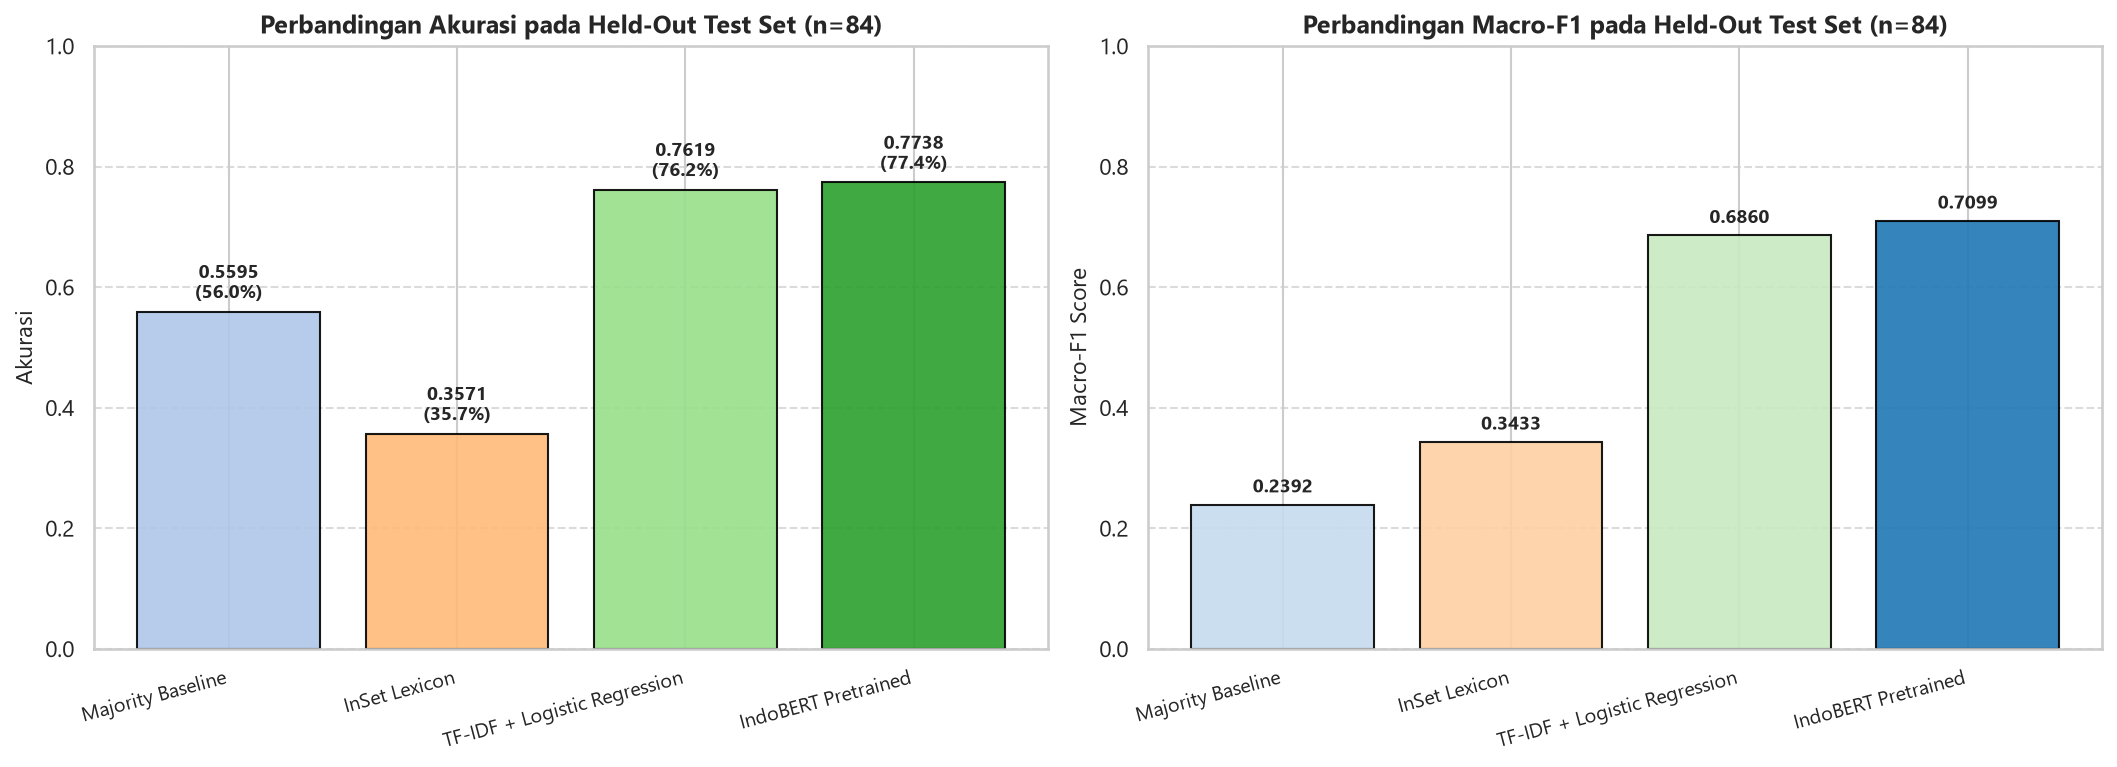

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

models = list(eval_comparison_df['Model'])
acc_values = eval_comparison_df['Accuracy (Dihitung)']
f1_values = eval_comparison_df['Macro-F1 (Dihitung)']

colors_acc = ['#AEC7E8', '#FFBB78', '#98DF8A', '#2CA02C']
colors_f1 = ['#C6DBEF', '#FDD0A2', '#C7E9C0', '#1F77B4']

x_indices = range(len(models))

# Subplot 1: Akurasi
bars_acc = axes[0].bar(x_indices, acc_values, color=colors_acc, edgecolor='black', alpha=0.9)
axes[0].set_title('Perbandingan Akurasi pada Held-Out Test Set (n=84)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Akurasi', fontsize=11)
axes[0].set_ylim(0, 1.0)
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(models, rotation=15, ha='right', fontsize=9.5)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars_acc:
    h = bar.get_height()
    axes[0].annotate(f'{h:.4f}\n({h*100:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# Subplot 2: Macro-F1
bars_f1 = axes[1].bar(x_indices, f1_values, color=colors_f1, edgecolor='black', alpha=0.9)
axes[1].set_title('Perbandingan Macro-F1 pada Held-Out Test Set (n=84)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Macro-F1 Score', fontsize=11)
axes[1].set_ylim(0, 1.0)
axes[1].set_xticks(x_indices)
axes[1].set_xticklabels(models, rotation=15, ha='right', fontsize=9.5)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars_f1:
    h = bar.get_height()
    axes[1].annotate(f'{h:.4f}',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

fig_path_bench = FIG_DIR / 'sentiment_benchmark.png'
plt.savefig(fig_path_bench, dpi=200)
print(f'Figur tersimpan: {fig_path_bench}')
plt.show()


## 4. Analisis Matriks Konfusi (Confusion Matrix Heatmaps)

Matriks konfusi mengungkap secara transparan bagaimana setiap model mendistribusikan prediksi terhadap ground-truth sentimen manusia (`positive`, `neutral`, `negative`).


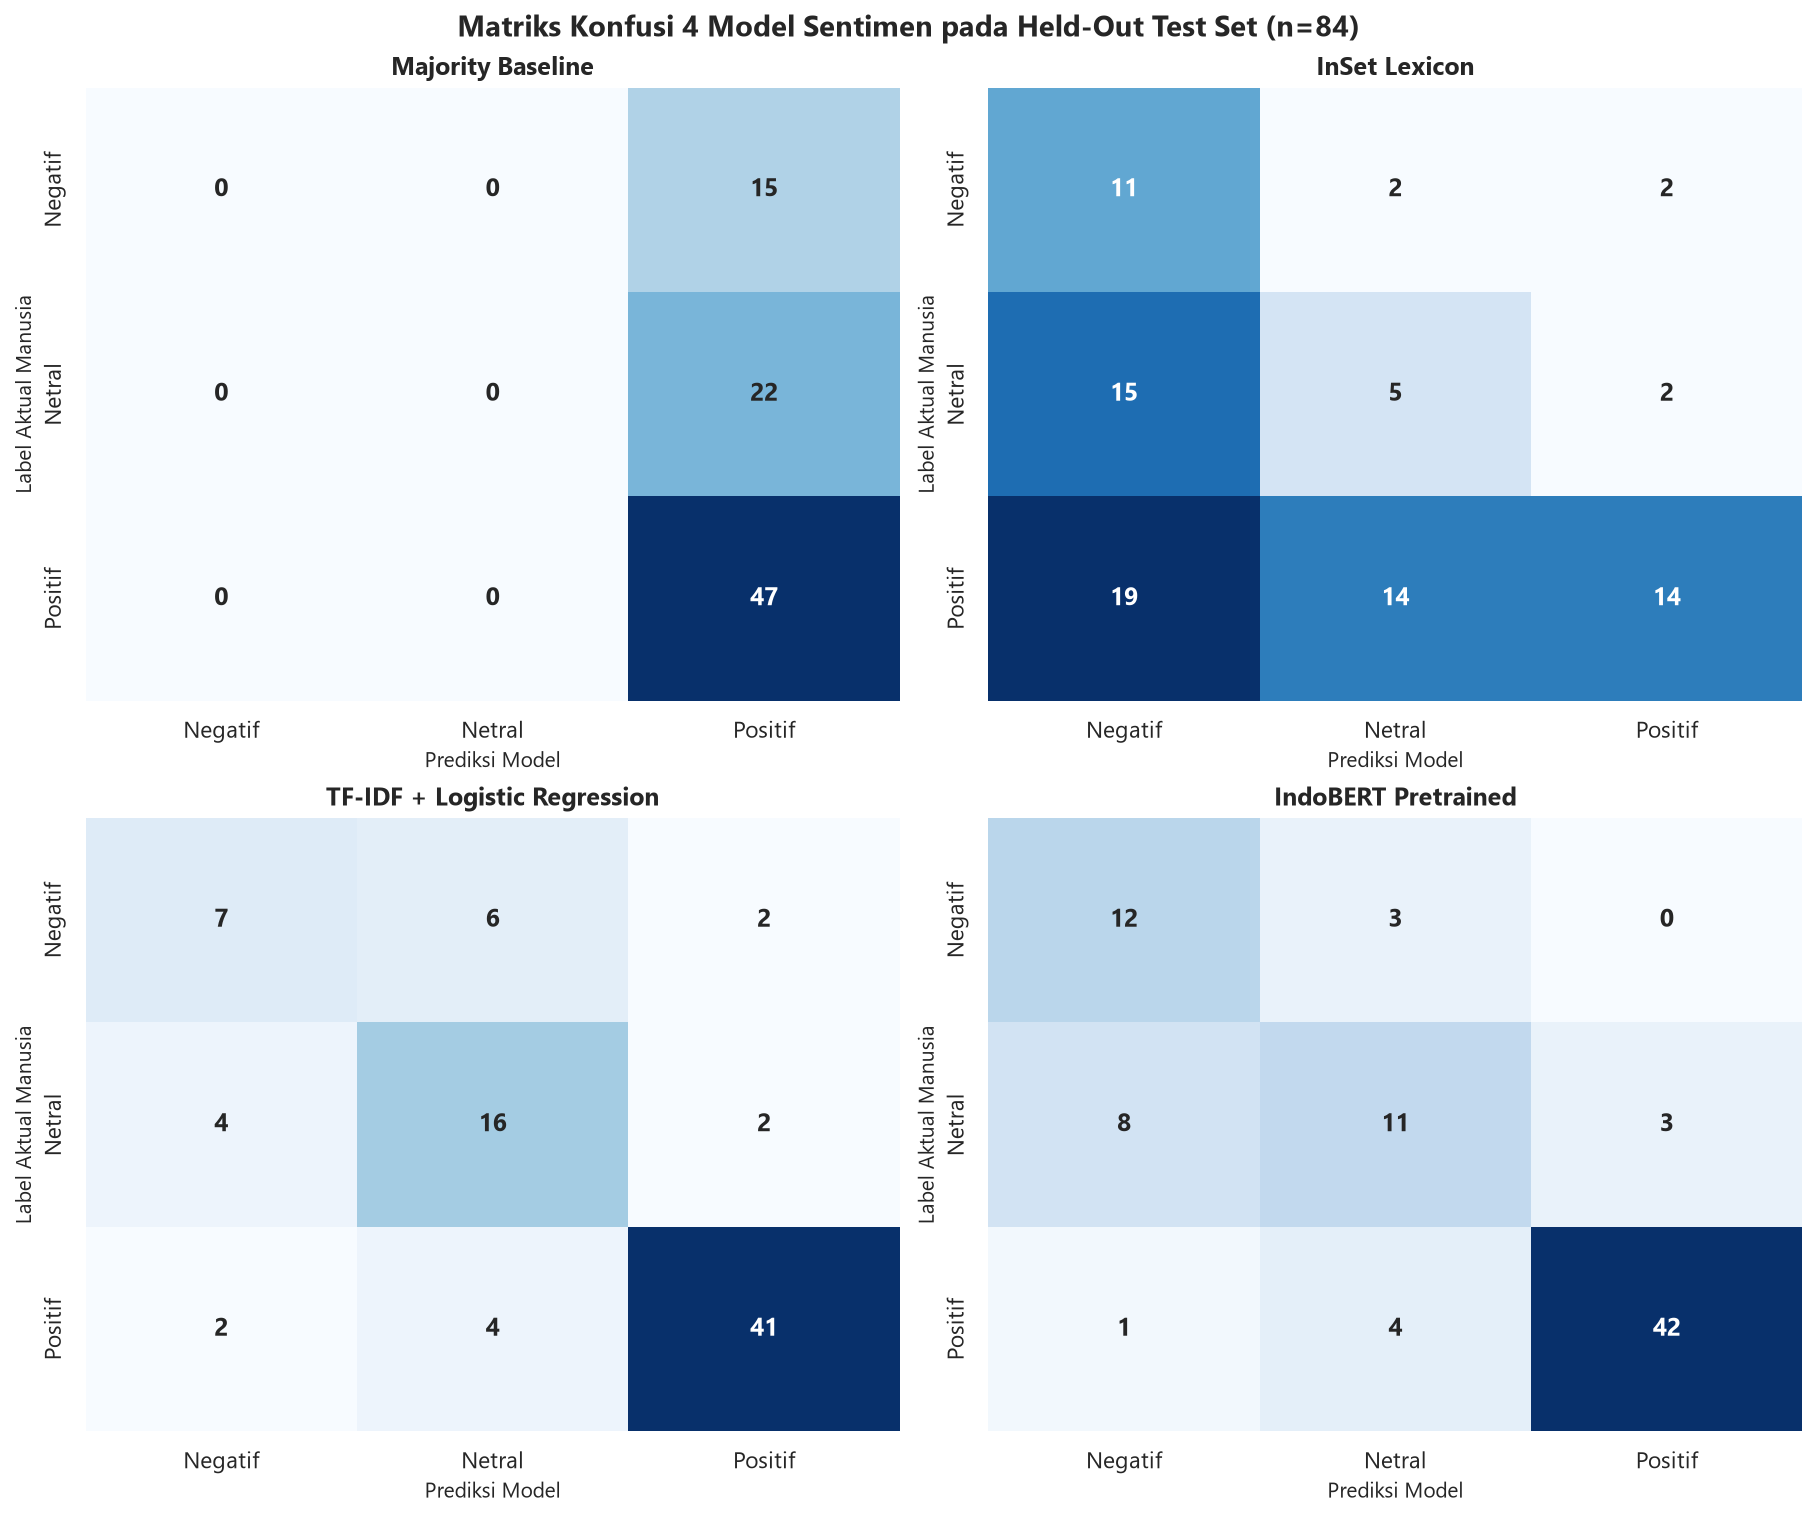

CLASSIFICATION REPORT: INDOBERT PRETRAINED
              precision    recall  f1-score   support

     Negatif       0.57      0.80      0.67        15
      Netral       0.61      0.50      0.55        22
     Positif       0.93      0.89      0.91        47

    accuracy                           0.77        84
   macro avg       0.71      0.73      0.71        84
weighted avg       0.78      0.77      0.77        84

CLASSIFICATION REPORT: TF-IDF + LOGISTIC REGRESSION
              precision    recall  f1-score   support

     Negatif       0.54      0.47      0.50        15
      Netral       0.62      0.73      0.67        22
     Positif       0.91      0.87      0.89        47

    accuracy                           0.76        84
   macro avg       0.69      0.69      0.69        84
weighted avg       0.77      0.76      0.76        84



In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout='constrained')
axes = axes.flatten()

order = ['negative', 'neutral', 'positive']

for idx, (model_name, col_name) in enumerate(models_dict.items()):
    ax = axes[idx]
    cm = confusion_matrix(pred_df['human_sentiment_label'], pred_df[col_name], labels=order)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Negatif', 'Netral', 'Positif'],
                yticklabels=['Negatif', 'Netral', 'Positif'],
                annot_kws={'size': 12, 'weight': 'bold'})
    
    ax.set_title(f'{model_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Prediksi Model', fontsize=10)
    ax.set_ylabel('Label Aktual Manusia', fontsize=10)

plt.suptitle('Matriks Konfusi 4 Model Sentimen pada Held-Out Test Set (n=84)', fontsize=14, fontweight='bold')
plt.show()

# Laporan Klasifikasi Rinci untuk IndoBERT dan TF-IDF
print('=' * 65)
print('CLASSIFICATION REPORT: INDOBERT PRETRAINED')
print('=' * 65)
print(classification_report(pred_df['human_sentiment_label'], pred_df['pred_indobert'], labels=order, target_names=['Negatif', 'Netral', 'Positif']))

print('=' * 65)
print('CLASSIFICATION REPORT: TF-IDF + LOGISTIC REGRESSION')
print('=' * 65)
print(classification_report(pred_df['human_sentiment_label'], pred_df['pred_tfidf_lr'], labels=order, target_names=['Negatif', 'Netral', 'Positif']))


## 5. Analisis Kesalahan Kualitatif (*Qualitative Error Analysis*)

Pemeriksaan kasus-kasus di mana IndoBERT berbeda dari ground truth manusia:
1. **Ambiguitas Kelas Netral**: Ulasan yang memuat pertanyaan faktual (misal: *"apakah bisa multi user?"*) sering diklasifikasikan sebagai negatif atau positif karena leksikon kata kerja.
2. **Sentimen Campuran / Bersyarat**: Ulasan yang memuji fitur tetapi mengeluhkan harga (*"Aplikasi bagus sekali tapi langganannya terlalu mahal bagi pemula"*) memuat kata-kata positif dan negatif secara bersamaan.


In [6]:
err_path = ROOT / 'data' / 'final' / 'sentiment_benchmark' / 'sentiment_error_analysis.csv'
assert err_path.is_file(), f'File error analysis tidak ditemukan: {err_path}'

err_df = pd.read_csv(err_path)
print(f'Total Kasus Kesalahan Model: {len(err_df)} kasus.')

# Kasus kesalahan IndoBERT
indobert_errors = err_df[err_df['model_name'] == 'IndoBERT Pretrained']
print(f'Kesalahan Klasifikasi IndoBERT: {len(indobert_errors)} dari 84 ulasan test ({len(indobert_errors)/84*100:.1f}% error rate).')

display(indobert_errors[['review_id', 'app_name', 'human_sentiment_label', 'predicted_sentiment', 'error_type', 'review_text_clean']].head(5))


Total Kasus Kesalahan Model: 130 kasus.
Kesalahan Klasifikasi IndoBERT: 19 dari 84 ulasan test (22.6% error rate).


,review_id,app_name,human_sentiment_label,predicted_sentiment,error_type,review_text_clean
2,af0dc1cd-08fc-4501-a781-45c9482dbd46,Zahir Certification,neutral,negative,neutral_as_negative,kenapa not to allowed terus ya? saya ga bisa l...
6,f1eef421-efb0-4793-ad21-0628a4a809a8,Zahir Simple Start,positive,negative,positive_as_negative,Past bisa bangkiiit aku
8,7746905f-df69-4e49-9f2a-c442c257fe9e,Zahir Simple Start,positive,neutral,positive_as_neutral,"Trimakasih kpd konsultan Zahir, yg bgitu tangg..."
10,4f8eb58b-a4b8-4c02-bfb3-b82a720ae098,POS X,positive,neutral,positive_as_neutral,"aplikasi yang di tunggu2, program kasir langsu..."
17,e0c075ae-283d-48d9-b2a9-ebdbbb3d4146,Zahir Online,negative,neutral,negative_as_neutral,tax tidak muncul di rincian. update: saya suda...


## 6. Opsi Pelatihan / Inferensi Ulang Model (*Optional Retraining Switch*)

Secara default, `RUN_RETRAINING = False` dan `RUN_INDOBERT_INFERENCE = False` untuk menjaga stabilitas execution time dan mencegah download model berukuran besar (~500MB). Opsi ini dapat diaktifkan jika ingin memverifikasi proses fitting TF-IDF + Logistic Regression secara langsung pada data development.


In [7]:
RUN_RETRAINING = False
RUN_INDOBERT_INFERENCE = False

if RUN_RETRAINING:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    
    print('Menjalankan pelatihan ulang TF-IDF + Logistic Regression...')
    
    # Ambil teks dan label dari split
    split_col = 'split' if 'split' in split_df.columns else 'benchmark_split'
    dev_mask = split_df[split_col] == 'development'
    test_mask = split_df[split_col] == 'test'
    
    gold_df = pd.read_csv(ROOT / 'data' / 'final' / 'playstore_gold_set_final.csv')
    merged_split = split_df.merge(gold_df[['review_id', 'review_text_clean']], on='review_id', how='left')
    
    X_dev = merged_split.loc[dev_mask, 'review_text_clean'].fillna('')
    y_dev = merged_split.loc[dev_mask, 'human_sentiment_label']
    
    X_test = merged_split.loc[test_mask, 'review_text_clean'].fillna('')
    y_test = merged_split.loc[test_mask, 'human_sentiment_label']
    
    # Fit vectorizer HANYA pada dev data untuk mencegah data leakage
    vec = TfidfVectorizer(ngram_range=(1, 2), max_features=1000, sublinear_tf=True)
    X_dev_vec = vec.fit_transform(X_dev)
    X_test_vec = vec.transform(X_test)
    
    clf = LogisticRegression(C=1.0, max_iter=500, random_state=42)
    clf.fit(X_dev_vec, y_dev)
    
    y_pred_new = clf.predict(X_test_vec)
    new_acc = accuracy_score(y_test, y_pred_new)
    new_f1 = f1_score(y_test, y_pred_new, average='macro', labels=['positive', 'neutral', 'negative'])
    
    print(f'[RETRAINED RESULT] TF-IDF + LogReg -> Accuracy: {new_acc:.4f}, Macro-F1: {new_f1:.4f}')
else:
    print('Mode Retraining dinonaktifkan (RUN_RETRAINING = False). Menggunakan artefak hasil benchmark resmi.')

if RUN_INDOBERT_INFERENCE:
    print('Menjalankan inferensi IndoBERT (membutuhkan koneksi internet dan GPU/CPU torch)...')
else:
    print('Mode Inferensi IndoBERT dinonaktifkan (RUN_INDOBERT_INFERENCE = False).')


Mode Retraining dinonaktifkan (RUN_RETRAINING = False). Menggunakan artefak hasil benchmark resmi.
Mode Inferensi IndoBERT dinonaktifkan (RUN_INDOBERT_INFERENCE = False).


## 7. Kesimpulan & Rekomendasi NLP

1. **Keunggulan IndoBERT**: IndoBERT mencapai performa tertinggi pada held-out test set dengan **Akurasi 77.38%** dan **Macro-F1 0.7099**, membuktikan bahwa contextual pretraining sangat efektif menangkap nuansa bahasa ulasan aplikasi Android.
2. **Kinerja Kompetitif TF-IDF + Logistic Regression**: TF-IDF + LR mencapai **Akurasi 76.19%** dan **Macro-F1 0.6860**, menjadikannya alternatif yang sangat efisien dan ringan (*lightweight*) untuk deployment pada sistem dengan keterbatasan resource komputasi.
3. **Keterbatasan Kamus Leksikon (InSet)**: InSet Lexicon mencatat akurasi terendah (**35.71%**), disebabkan oleh banyaknya kosakata slang lokal, istilah domain akuntansi (*pembukuan, kasir, faktur, neraca*), dan ekspresi ulasan singkat yang tidak tercakup dalam kamus umum.
4. **Pentingnya Held-Out Set**: Pemisahan 84 ulasan test secara independen memastikan seluruh metrik bebas dari optimisme semu (*overfitting/data leakage*), memberikan estimasi generalisasi yang jujur dan ilmiah.
